<a href="https://colab.research.google.com/github/likhithakm-again/tsaf-lab05/blob/main/Lab05_SARIMA_1RUA24CSE0223.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install pandas numpy matplotlib statsmodels scikit-learn

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [3]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

df = pd.read_csv(url)
df["Month"] = pd.to_datetime(df["Month"])
df = df.set_index("Month")

series = df["Passengers"].asfreq("MS").astype(float)

print("Dataset: AirPassengers")
print("Frequency: Monthly")
print("Total observations:", len(series))
print("Start date:", series.index.min())
print("End date:", series.index.max())
print("Missing values:", series.isna().sum())

print("\nFirst five observations:")
print(series.head())

Dataset: AirPassengers
Frequency: Monthly
Total observations: 144
Start date: 1949-01-01 00:00:00
End date: 1960-12-01 00:00:00
Missing values: 0

First five observations:
Month
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
Freq: MS, Name: Passengers, dtype: float64


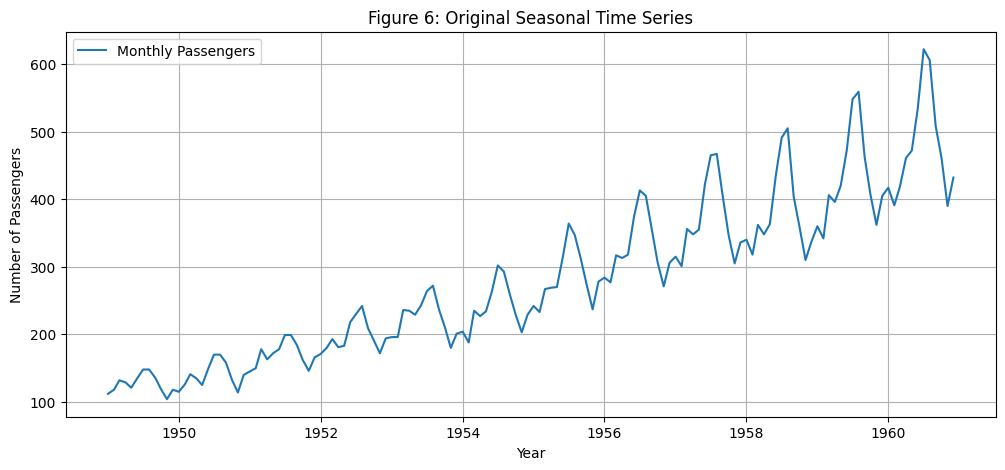

In [4]:
plt.figure(figsize=(12, 5))
plt.plot(series, label="Monthly Passengers")
plt.title("Figure 6: Original Seasonal Time Series")
plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True)
plt.show()

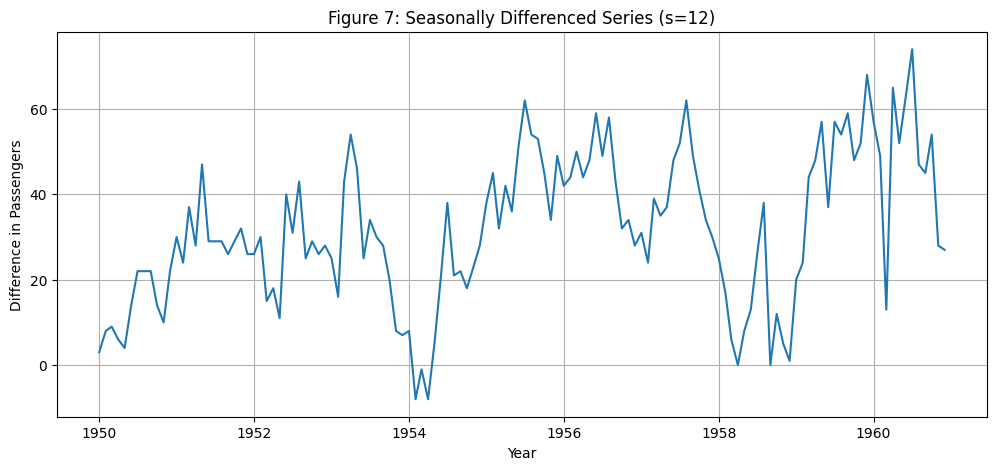

Original observations: 144
Seasonally differenced observations: 132

Original series ADF statistic: 0.8153688792060498
Original series p-value: 0.991880243437641

Seasonally differenced ADF statistic: -3.383020726492481
Seasonally differenced p-value: 0.011551493085514952


In [5]:
seasonal_diff = series.diff(12).dropna()

plt.figure(figsize=(12, 5))
plt.plot(seasonal_diff)
plt.title("Figure 7: Seasonally Differenced Series (s=12)")
plt.xlabel("Year")
plt.ylabel("Difference in Passengers")
plt.grid(True)
plt.show()

print("Original observations:", len(series))
print("Seasonally differenced observations:", len(seasonal_diff))

adf_original = adfuller(series)
adf_seasonal = adfuller(seasonal_diff)

print("\nOriginal series ADF statistic:", adf_original[0])
print("Original series p-value:", adf_original[1])

print("\nSeasonally differenced ADF statistic:", adf_seasonal[0])
print("Seasonally differenced p-value:", adf_seasonal[1])

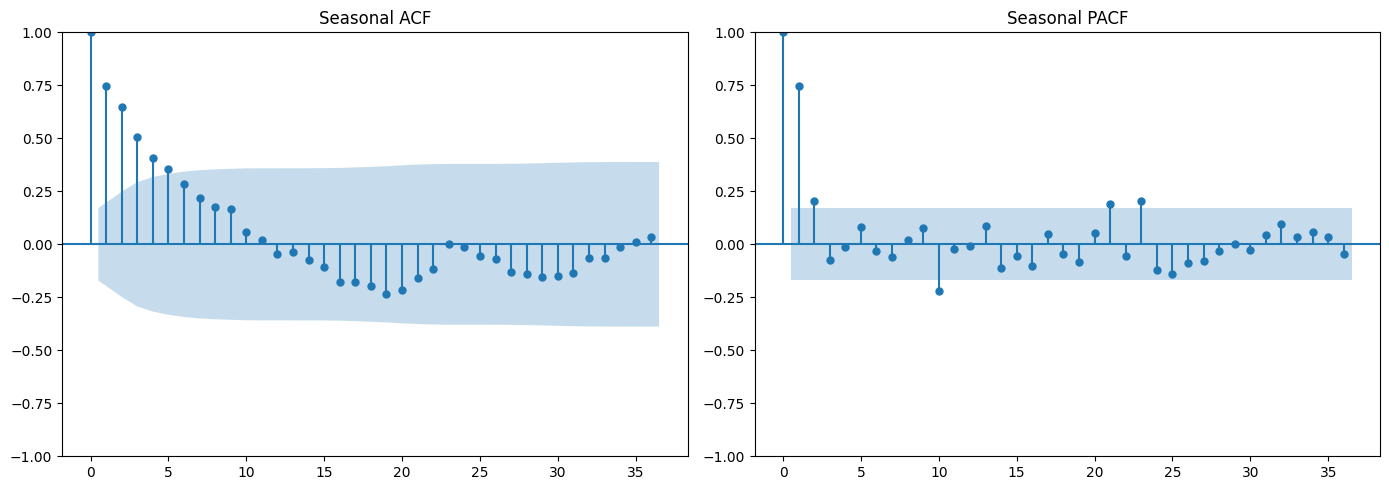

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(seasonal_diff, ax=axes[0], lags=36)
plot_pacf(seasonal_diff, ax=axes[1], lags=36, method="ywm")

axes[0].set_title("Seasonal ACF")
axes[1].set_title("Seasonal PACF")

plt.tight_layout()
plt.show()

In [7]:
train_size = int(len(series) * 0.80)

train = series.iloc[:train_size]
test = series.iloc[train_size:]

print("Total observations:", len(series))
print("Training observations:", len(train))
print("Testing observations:", len(test))

print("Training period:", train.index.min(), "to", train.index.max())
print("Testing period:", test.index.min(), "to", test.index.max())

Total observations: 144
Training observations: 115
Testing observations: 29
Training period: 1949-01-01 00:00:00 to 1958-07-01 00:00:00
Testing period: 1958-08-01 00:00:00 to 1960-12-01 00:00:00


In [8]:
model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

model_fit = model.fit(disp=False)

print(model_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -323.801
Date:                            Thu, 29 Oct 2026   AIC                            657.601
Time:                                    14:06:50   BIC                            669.988
Sample:                                01-01-1949   HQIC                           662.592
                                     - 07-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8224      0.184     -4.461      0.000      -1.184      -0.461
ma.L1          0.7176      0.224   

In [9]:
forecast = model_fit.forecast(steps=len(test))

mae = mean_absolute_error(test, forecast)
rmse = np.sqrt(mean_squared_error(test, forecast))

print("Model: SARIMA(1,1,1)(1,1,1,12)")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

Model: SARIMA(1,1,1)(1,1,1,12)
MAE: 25.2680
RMSE: 31.7873


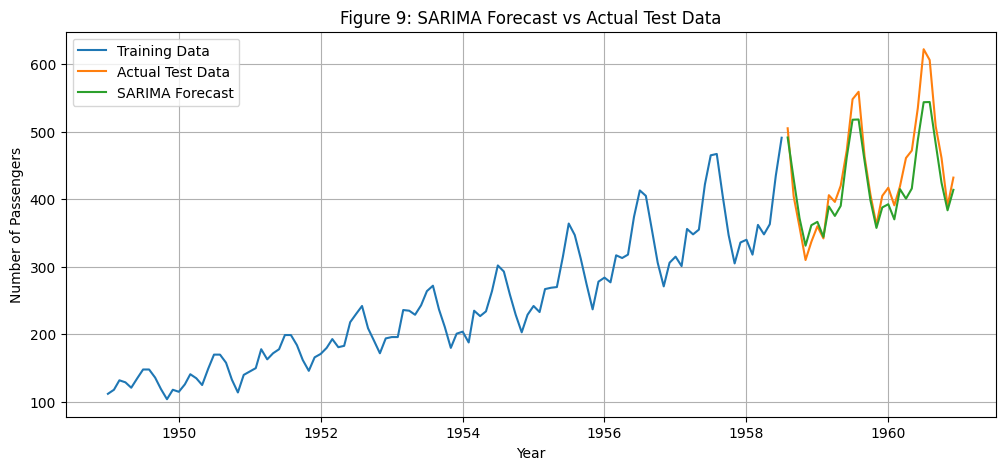

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(train.index, train, label="Training Data")
plt.plot(test.index, test, label="Actual Test Data")
plt.plot(test.index, forecast, label="SARIMA Forecast")

plt.title("Figure 9: SARIMA Forecast vs Actual Test Data")
plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True)
plt.show()

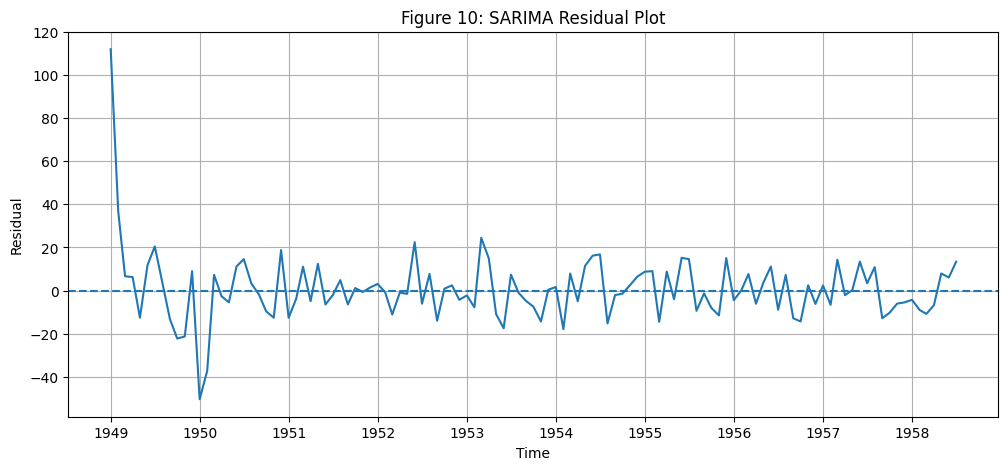

Residual mean: 0.5521
Residual standard deviation: 15.9802


In [11]:
residuals = model_fit.resid

plt.figure(figsize=(12, 5))
plt.plot(residuals)
plt.axhline(y=0, linestyle="--")
plt.title("Figure 10: SARIMA Residual Plot")
plt.xlabel("Time")
plt.ylabel("Residual")
plt.grid(True)
plt.show()

print("Residual mean:", round(residuals.mean(), 4))
print("Residual standard deviation:", round(residuals.std(), 4))

### Independent Task 5.1: Compare SARIMA orders

In [12]:
sarima_orders = [
    ((1, 1, 1), (1, 1, 1, 12)),
    ((1, 1, 1), (0, 1, 1, 12)),
    ((2, 1, 1), (1, 1, 1, 12))
]

sarima_results = []

for order, seasonal_order in sarima_orders:
    try:
        fitted = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False)

        predictions = fitted.forecast(steps=len(test))

        sarima_results.append({
            "Order": str(order),
            "Seasonal Order": str(seasonal_order),
            "AIC": fitted.aic,
            "MAE": mean_absolute_error(test, predictions),
            "RMSE": np.sqrt(mean_squared_error(test, predictions))
        })

    except Exception as e:
        print(f"Model {order}, {seasonal_order} failed: {e}")

sarima_comparison = pd.DataFrame(sarima_results)

print(sarima_comparison.round(4).to_string(index=False))

if not sarima_comparison.empty:
    print("\nModel with the lowest test RMSE:")
    print(
        sarima_comparison.loc[
            sarima_comparison["RMSE"].idxmin()
        ].to_string()
    )

    print("\nModel with the lowest test MAE:")
    print(
        sarima_comparison.loc[
            sarima_comparison["MAE"].idxmin()
        ].to_string()
    )

    Order Seasonal Order      AIC     MAE    RMSE
(1, 1, 1)  (1, 1, 1, 12) 657.6013 25.2680 31.7873
(1, 1, 1)  (0, 1, 1, 12) 659.3327 23.3679 29.9231
(2, 1, 1)  (1, 1, 1, 12) 659.2522 26.4958 32.9894

Model with the lowest test RMSE:
Order                 (1, 1, 1)
Seasonal Order    (0, 1, 1, 12)
AIC                  659.332685
MAE                   23.367858
RMSE                  29.923085

Model with the lowest test MAE:
Order                 (1, 1, 1)
Seasonal Order    (0, 1, 1, 12)
AIC                  659.332685
MAE                   23.367858
RMSE                  29.923085


### Independent Task 5.2: Seasonal period

A seasonal period of \(s=12\) is appropriate for monthly data with annual seasonality because there are 12 months in a year, and the model can learn patterns that repeat every 12 observations. For example, monthly retail sales may increase every December because of holiday shopping. A seasonal period of \(s=7\) is appropriate for daily data with a weekly pattern, such as website traffic that changes between weekdays and weekends. A seasonal period of \(s=24\) may be appropriate for hourly electricity demand or traffic measurements when a daily pattern repeats every 24 hours. The seasonal period must match the sampling frequency and the recurring pattern present in the data.

### Independent Task 5.3: ARIMA vs SARIMA

                  Model     MAE    RMSE
           ARIMA(2,1,2) 63.5453 82.5130
SARIMA(1,1,1)(1,1,1,12) 25.2680 31.7873


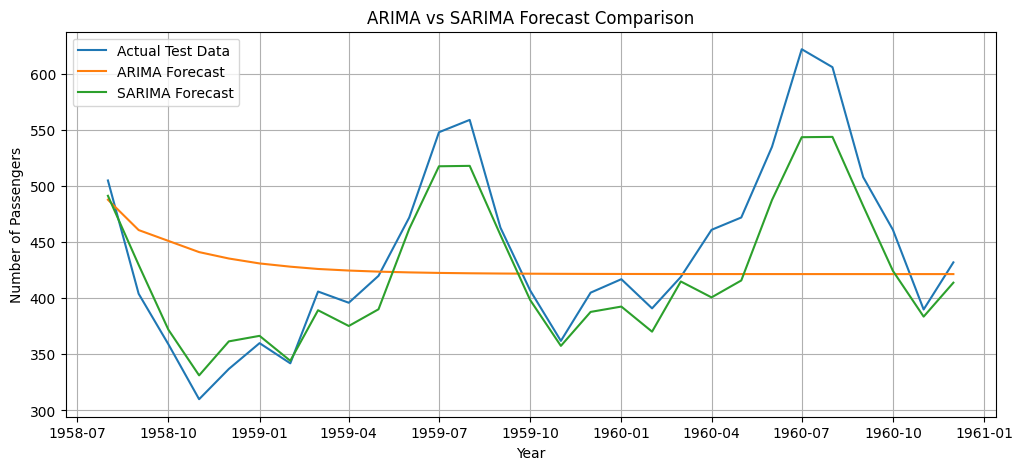

In [14]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

arima_fit = ARIMA(train, order=(2, 1, 2)).fit()
arima_forecast = arima_fit.forecast(steps=len(test))

sarima_fit = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_forecast = sarima_fit.forecast(steps=len(test))

comparison = pd.DataFrame([
    {
        "Model": "ARIMA(2,1,2)",
        "MAE": mean_absolute_error(test, arima_forecast),
        "RMSE": np.sqrt(mean_squared_error(test, arima_forecast))
    },
    {
        "Model": "SARIMA(1,1,1)(1,1,1,12)",
        "MAE": mean_absolute_error(test, sarima_forecast),
        "RMSE": np.sqrt(mean_squared_error(test, sarima_forecast))
    }
])

print(comparison.round(4).to_string(index=False))

plt.figure(figsize=(12, 5))
plt.plot(test.index, test, label="Actual Test Data")
plt.plot(test.index, arima_forecast, label="ARIMA Forecast")
plt.plot(test.index, sarima_forecast, label="SARIMA Forecast")

plt.title("ARIMA vs SARIMA Forecast Comparison")
plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True)
plt.show()

The ARIMA(2,1,2) model from Lab 4 and the SARIMA(1,1,1)(1,1,1,12) model were evaluated using the same AirPassengers test observations. ARIMA produced an MAE of 63.5453 and an RMSE of 82.5130. In comparison, SARIMA achieved an MAE of 25.2680 and an RMSE of 31.7873. The SARIMA model therefore produced substantially lower forecasting errors on the test set. The MAE decreased by approximately 60.2%, while the RMSE decreased by approximately 61.5% compared with ARIMA. The improvement indicates that incorporating seasonal components helps the model represent the recurring annual passenger patterns more effectively. For this dataset and evaluation period, SARIMA performed better than the selected non seasonal ARIMA model.

### Independent Task 5.4: Effect of seasonal differencing

 Seasonal Differencing D      AIC     MAE    RMSE
                       0 721.6842 18.6973 22.3992
                       1 657.6013 25.2680 31.7873


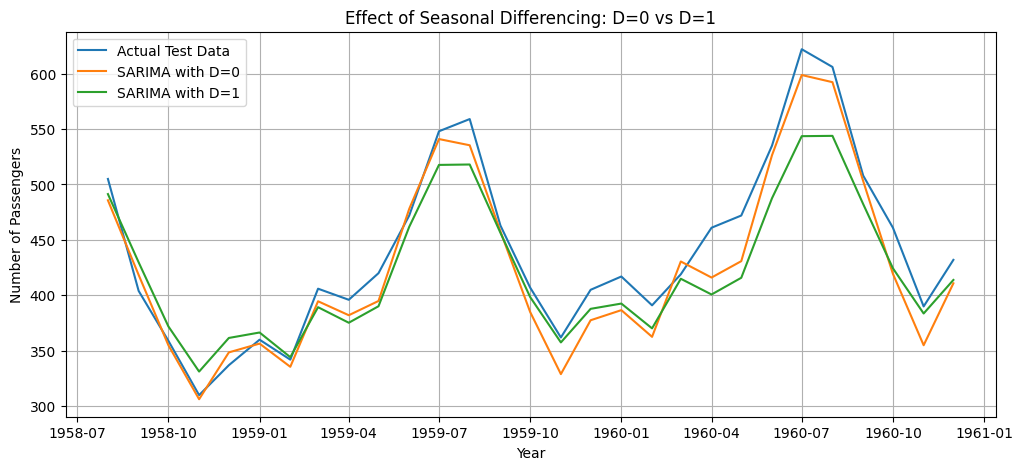

In [15]:
seasonal_diff_results = []
seasonal_diff_forecasts = {}

for D in [0, 1]:
    fitted = SARIMAX(
        train,
        order=(1, 1, 1),
        seasonal_order=(1, D, 1, 12),
        enforce_stationarity=False,
        enforce_invertibility=False
    ).fit(disp=False)

    predictions = fitted.forecast(steps=len(test))
    seasonal_diff_forecasts[D] = predictions

    seasonal_diff_results.append({
        "Seasonal Differencing D": D,
        "AIC": fitted.aic,
        "MAE": mean_absolute_error(test, predictions),
        "RMSE": np.sqrt(mean_squared_error(test, predictions))
    })

print(
    pd.DataFrame(seasonal_diff_results)
    .round(4)
    .to_string(index=False)
)

plt.figure(figsize=(12, 5))
plt.plot(test.index, test, label="Actual Test Data")
plt.plot(
    test.index,
    seasonal_diff_forecasts[0],
    label="SARIMA with D=0"
)
plt.plot(
    test.index,
    seasonal_diff_forecasts[1],
    label="SARIMA with D=1"
)

plt.title("Effect of Seasonal Differencing: D=0 vs D=1")
plt.xlabel("Year")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True)
plt.show()

The SARIMA model was evaluated using seasonal differencing orders of D=0 and D=1 while keeping the other parameters unchanged. With D=0, the model achieved an AIC of 721.6842, an MAE of 18.6973, and an RMSE of 22.3992. With D=1, the AIC decreased to 657.6013, while the MAE increased to 25.2680 and the RMSE increased to 31.7873. Thus, the model with D=0 achieved lower test forecasting errors, whereas the model with D=1 achieved a lower AIC. This demonstrates that seasonal differencing does not automatically improve test accuracy for every model configuration. The results should be interpreted alongside stationarity analysis, residual diagnostics, and the forecast plot. For this particular split and these parameter settings, D=0 provided better test accuracy according to MAE and RMSE.

### Independent Task 5.5: A different seasonal real-world dataset

Dataset: Mauna Loa Atmospheric CO2
Source: statsmodels CO2 dataset
Original frequency: Weekly
Modelling frequency: Monthly
Seasonal period: 12 months
Total monthly observations: 526
Missing values: 0


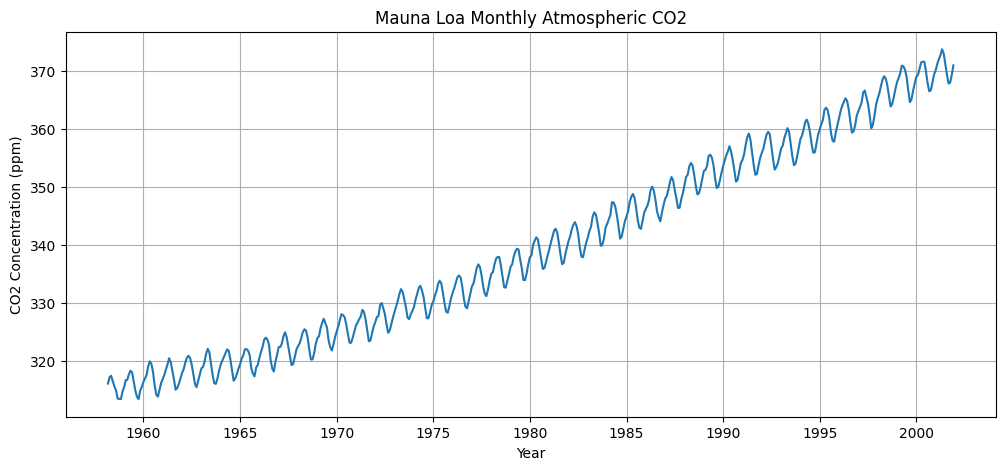

In [16]:
import statsmodels.api as sm

co2_data = sm.datasets.co2.load_pandas().data

co2_series = co2_data["co2"].resample("MS").mean()

co2_series = co2_series.interpolate(method="time").astype(float)

print("Dataset: Mauna Loa Atmospheric CO2")
print("Source: statsmodels CO2 dataset")
print("Original frequency: Weekly")
print("Modelling frequency: Monthly")
print("Seasonal period: 12 months")
print("Total monthly observations:", len(co2_series))
print("Missing values:", co2_series.isna().sum())

plt.figure(figsize=(12, 5))
plt.plot(co2_series)
plt.title("Mauna Loa Monthly Atmospheric CO2")
plt.xlabel("Year")
plt.ylabel("CO2 Concentration (ppm)")
plt.grid(True)
plt.show()

In [17]:
co2_train_size = int(len(co2_series) * 0.80)

co2_train = co2_series.iloc[:co2_train_size]
co2_test = co2_series.iloc[co2_train_size:]

print("Training observations:", len(co2_train))
print("Testing observations:", len(co2_test))
print("Training period:", co2_train.index.min(),
      "to", co2_train.index.max())
print("Testing period:", co2_test.index.min(),
      "to", co2_test.index.max())

co2_model = SARIMAX(
    co2_train,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

co2_fit = co2_model.fit(disp=False)

print(co2_fit.summary())

co2_forecast = co2_fit.forecast(steps=len(co2_test))

co2_mae = mean_absolute_error(co2_test, co2_forecast)
co2_rmse = np.sqrt(mean_squared_error(co2_test, co2_forecast))

print("\nCO2 SARIMA Results")
print("Order: (1,1,1)")
print("Seasonal order: (1,1,1,12)")
print(f"MAE: {co2_mae:.4f}")
print(f"RMSE: {co2_rmse:.4f}")

Training observations: 420
Testing observations: 106
Training period: 1958-03-01 00:00:00 to 1993-02-01 00:00:00
Testing period: 1993-03-01 00:00:00 to 2001-12-01 00:00:00
                                     SARIMAX Results                                      
Dep. Variable:                                co2   No. Observations:                  420
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                 -85.986
Date:                            Thu, 29 Oct 2026   AIC                            181.972
Time:                                    14:13:15   BIC                            201.841
Sample:                                03-01-1958   HQIC                           189.846
                                     - 02-01-1993                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
---------------------

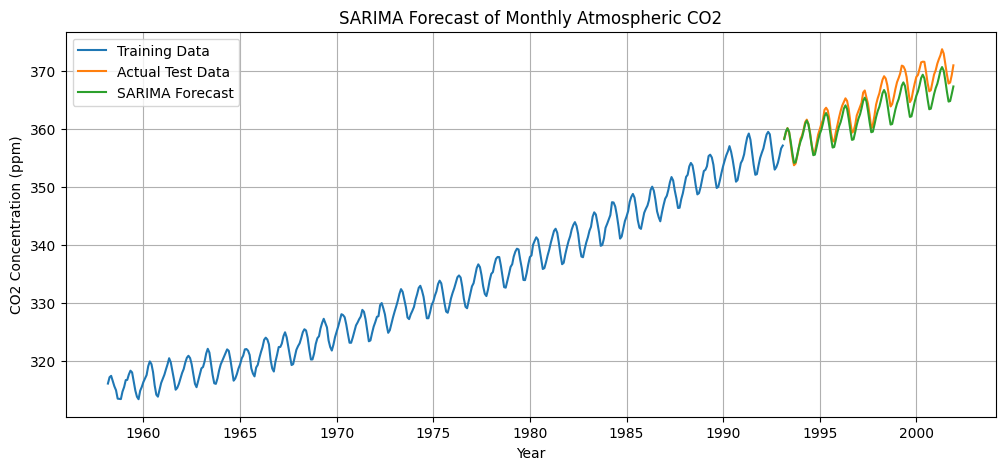

In [18]:
plt.figure(figsize=(12, 5))

plt.plot(co2_train.index, co2_train, label="Training Data")
plt.plot(co2_test.index, co2_test, label="Actual Test Data")
plt.plot(co2_test.index, co2_forecast, label="SARIMA Forecast")

plt.title("SARIMA Forecast of Monthly Atmospheric CO2")
plt.xlabel("Year")
plt.ylabel("CO2 Concentration (ppm)")
plt.legend()
plt.grid(True)
plt.show()

The Mauna Loa atmospheric CO₂ dataset was selected as an additional real world time series. The original weekly measurements were converted into monthly averages, producing 526 monthly observations with no missing values after interpolation. The data were divided chronologically into 420 training observations from March 1958 to February 1993 and 106 testing observations from March 1993 to December 2001. A SARIMA(1,1,1)(1,1,1,12) model was fitted to the training data, using a seasonal period of 12 to represent annual patterns in the monthly measurements. The model achieved an MAE of 1.8524 and an RMSE of 2.1840. These values indicate that the forecasts differed from the actual CO₂ concentrations by relatively small amounts on the dataset's measurement scale, which is parts per million. The forecast plot can be used to assess how well the model follows the long term increase and seasonal variations in atmospheric CO₂. This experiment demonstrates that SARIMA can be applied to a different real world dataset with seasonal characteristics, although the results depend on the chosen model configuration and test period.